<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Final Weights: [ 0.78474781 -0.51165572]
Final Bias: -0.4
Weight Updates: [10, 4, 6, 10, 4, 7, 10, 6, 6, 6, 6, 6, 6, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 3, 4, 5]


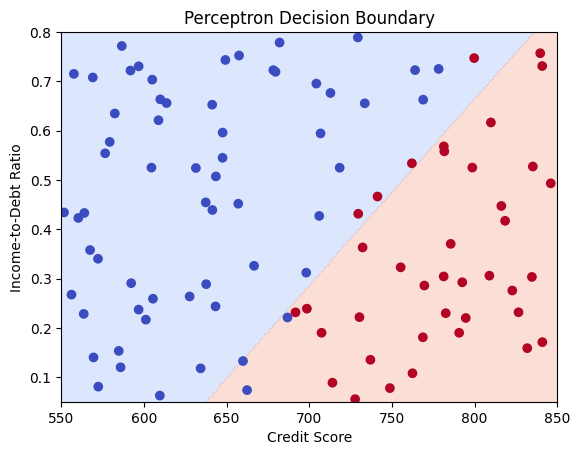

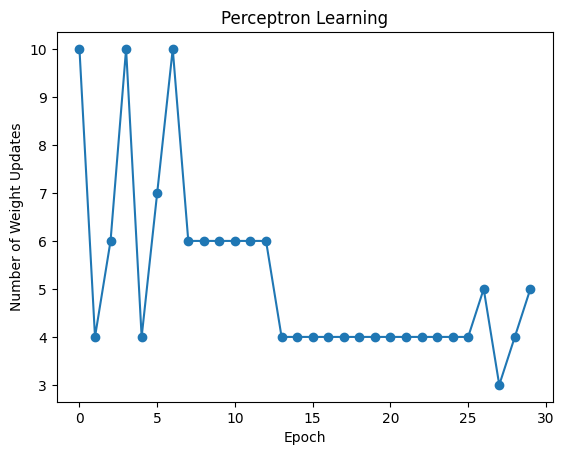


XOR Predictions:
[1 1 0 0]
Actual XOR: [0 1 1 0]

Step: [0 0 1 1 1]
Sigmoid: [0.11920292 0.26894142 0.5        0.73105858 0.88079708]
ReLU: [0 0 0 1 2]


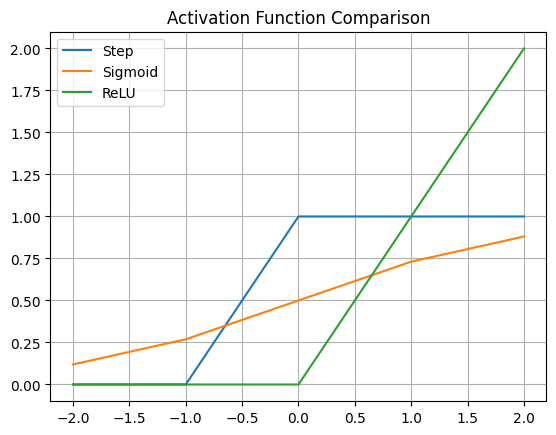

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

# 1. Generate Loan Dataset
X = np.column_stack([
    np.random.uniform(550,850,100),
    np.random.uniform(0.05,0.8,100)
])

y = (X[:,0] > 650+180*X[:,1]).astype(int)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Perceptron Implementation
weights = np.zeros(2)
bias = 0
lr = 0.1

updates = []

for epoch in range(30):

    errors = 0

    for xi,target in zip(X_scaled,y):

        weighted_sum = np.dot(xi,weights)+bias

        prediction = int(weighted_sum >= 0)

        error = target-prediction

        if error != 0:

            weights += lr*error*xi
            bias += lr*error

            errors += 1

    updates.append(errors)

    if errors == 0:
        break

print("Final Weights:",weights)
print("Final Bias:",bias)
print("Weight Updates:",updates)

# 3. Decision Boundary
xx,yy = np.meshgrid(
    np.linspace(550,850,200),
    np.linspace(0.05,0.8,200)
)

grid = np.c_[xx.ravel(),yy.ravel()]

prediction = (
    scaler.transform(grid)@weights+bias >= 0
).reshape(xx.shape)

plt.contourf(xx,yy,prediction,alpha=0.3,cmap='coolwarm')

plt.scatter(X[:,0],X[:,1],c=y,cmap='coolwarm')

plt.xlabel("Credit Score")
plt.ylabel("Income-to-Debt Ratio")
plt.title("Perceptron Decision Boundary")
plt.show()

# Weight Updates Graph
plt.plot(updates,marker='o')
plt.xlabel("Epoch")
plt.ylabel("Number of Weight Updates")
plt.title("Perceptron Learning")
plt.show()

# 4. XOR Dataset
XOR = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
])

YOR = np.array([0,1,1,0])

w = np.zeros(2)
b = 0

for epoch in range(20):

    for xi,target in zip(XOR,YOR):

        pred = int(np.dot(w,xi)+b >= 0)
        error = target-pred

        w += 0.1*error*xi
        b += 0.1*error

print("\nXOR Predictions:")
print((XOR@w+b >= 0).astype(int))

print("Actual XOR:",YOR)

# 5. Activation Functions
z = np.array([-2,-1,0,1,2])

step = (z>=0).astype(int)
sigmoid = 1/(1+np.exp(-z))
relu = np.maximum(0,z)

print("\nStep:",step)
print("Sigmoid:",sigmoid)
print("ReLU:",relu)

plt.plot(z,step,label="Step")
plt.plot(z,sigmoid,label="Sigmoid")
plt.plot(z,relu,label="ReLU")

plt.title("Activation Function Comparison")
plt.legend()
plt.grid()
plt.show()